In [1]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.12.14 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2962
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


# Task 4 — Random Forests & Ensembles

**Aldiyar Yeleu · MOP 3231 · SEED = 2962** (последние четыре цифры student ID).

Spam = 1; legitimate = 0. Все сравнения accuracy используют одинаковые пять
стратифицированных folds. Стандартное отклонение вычисляется с `ddof=0`.
Порог и число раундов выбираются только по обучающей выборке.

In [3]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

In [4]:
import math
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import cross_val_predict, cross_validate

assert X.shape == (4204, 57)
assert X_train.shape == (3153, 57) and X_test.shape == (1051, 57)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 6)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})

def fold_table(score_map):
    rows = {}
    for name, values in score_map.items():
        values = np.asarray(values)
        rows[name] = dict(zip([f'fold {i}' for i in range(1, 6)], values))
        rows[name].update(mean=values.mean(), std=values.std(ddof=0))
    return pd.DataFrame.from_dict(rows, orient='index')

def paired_table(difference_map):
    return fold_table(difference_map)

def compare_text(name, differences):
    d = np.asarray(differences)
    mean, std = d.mean(), d.std(ddof=0)
    if abs(mean) <= std:
        result = 'разность внутри разброса folds; данные не позволяют назвать победителя'
    elif mean > 0:
        result = 'средняя accuracy первой модели выше, и разность выходит за разброс folds'
    else:
        result = 'средняя accuracy первой модели ниже, и разность выходит за разброс folds'
    return f'{name}: mean = {mean:.6f}, std = {std:.6f}; {result}.'

cv_scores = {}
def get_cv_scores(name, model):
    if name not in cv_scores:
        cv_scores[name] = cross_validate(model, X_train, y_train, cv=cv,
                                         scoring='accuracy')['test_score']
    return cv_scores[name]

## Part 1 — Bagging and out-of-bag estimates

In [5]:
def oob_mask(sample_indices, n_samples):
    """Return a boolean mask of rows absent from the bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask

In [6]:
assert np.array_equal(oob_mask([0, 2, 2], 5), [False, True, False, True, True])
assert np.array_equal(oob_mask([], 3), [True, True, True])
assert np.array_equal(oob_mask(np.array([3, 0]), 4), [False, True, True, False])
assert oob_mask([], 0).shape == (0,) and oob_mask([], 0).dtype == bool
indices_example = np.array([0, 2, 2])
indices_copy = indices_example.copy()
oob_mask(indices_example, 5)
assert np.array_equal(indices_example, indices_copy)
print('oob_mask: примеры, пустой ввод и неизменность аргумента проверены.')

bag.fit(X_train, y_train)
n_train = len(y_train)
oob_shares = []
oob_votes = np.zeros((n_train, 2), dtype=int)
for estimator, sample_indices in zip(bag.estimators_, bag.estimators_samples_):
    mask = oob_mask(sample_indices, n_train)
    oob_shares.append(mask.mean())
    rows = np.flatnonzero(mask)
    predictions = estimator.predict(X_train[mask]).astype(int)
    oob_votes[rows, predictions] += 1
assert np.all(oob_votes.sum(axis=1) > 0)
manual_oob_accuracy = accuracy_score(y_train, oob_votes.argmax(axis=1))
formula_oob = (1 - 1 / n_train) ** n_train
display(pd.DataFrame({'empirical': [np.mean(oob_shares), 1-np.mean(oob_shares)],
                      'formula': [formula_oob, 1-formula_oob]}, index=['OOB share', 'in-bag share']))
display(pd.DataFrame({'manual OOB accuracy': [manual_oob_accuracy],
                      'bag.oob_score_': [bag.oob_score_]}))
assert manual_oob_accuracy == bag.oob_score_

oob_mask: примеры, пустой ввод и неизменность аргумента проверены.


,empirical,formula
OOB share,0.367704,0.367821
in-bag share,0.632296,0.632179


,manual OOB accuracy,bag.oob_score_
0,0.93974,0.93974


In [7]:
for name, model in [('tree', tree), ('bag', bag), ('rf', rf), ('lr', lr), ('bag_lr', bag_lr)]:
    get_cv_scores(name, model)
display(fold_table({name: cv_scores[name] for name in ['tree', 'bag', 'rf', 'lr', 'bag_lr']}))
part1_differences = {
    'bag − tree': cv_scores['bag'] - cv_scores['tree'],
    'rf − tree': cv_scores['rf'] - cv_scores['tree'],
    'bag_lr − lr': cv_scores['bag_lr'] - cv_scores['lr']}
display(paired_table(part1_differences))

rf.fit(X_train, y_train)
rf_test_accuracy = rf.score(X_test, y_test)
rf_test_se = np.sqrt(rf_test_accuracy*(1-rf_test_accuracy)/len(y_test))
display(pd.DataFrame({'estimate': [rf.oob_score_, cv_scores['rf'].mean(), rf_test_accuracy],
                      'spread': [np.nan, cv_scores['rf'].std(ddof=0), rf_test_se]},
                     index=['OOB accuracy', 'CV accuracy (spread = fold std)',
                            'test accuracy (spread = standard error)']))
oob_cv_gap = abs(rf.oob_score_ - cv_scores['rf'].mean())
oob_cv_agree = oob_cv_gap <= cv_scores['rf'].std(ddof=0)
display(Markdown('\n\n'.join(compare_text(name, diff) for name, diff in part1_differences.items())))
display(Markdown(
    'Bagging усредняет нестабильные деревья и уменьшает их дисперсию: разные bootstrap-выборки '
    'дают разные границы, а большинство голосов сглаживает их. Logistic regression обычно '
    'стабильнее дерева, поэтому усреднение её bootstrap-копий даёт меньше пользы; log1p и scaler '
    'обучаются внутри каждого fold, а не на всей выборке.\n\n'
    f'OOB и CV леса {"согласуются" if oob_cv_agree else "не согласуются"} по правилу задания: '
    f'|OOB − CV| = {oob_cv_gap:.6f}, std(CV) = {cv_scores["rf"].std(ddof=0):.6f}. '
    f'Test accuracy = {rf_test_accuracy:.6f}, SE = {rf_test_se:.6f}; '
    f'отклонение OOB от test = {abs(rf.oob_score_-rf_test_accuracy):.6f} '
    f'({abs(rf.oob_score_-rf_test_accuracy)/rf_test_se:.2f} SE), '
    f'CV от test = {abs(cv_scores["rf"].mean()-rf_test_accuracy):.6f} '
    f'({abs(cv_scores["rf"].mean()-rf_test_accuracy)/rf_test_se:.2f} SE). '
    'Это три оценки по разным наборам предсказаний; SE test описывает только неопределённость '
    'доли правильных ответов на данном test split.'))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
tree,0.901743,0.920761,0.904913,0.901587,0.909524,0.907706,0.007135
bag,0.931854,0.939778,0.939778,0.942857,0.949206,0.940695,0.005603
rf,0.933439,0.950872,0.941363,0.949206,0.958730,0.946722,0.008634
lr,0.939778,0.936609,0.938193,0.930159,0.939683,0.936884,0.003556
bag_lr,0.939778,0.938193,0.936609,0.931746,0.939683,0.937202,0.002963


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
bag − tree,0.030111,0.019017,0.034865,0.041270,0.039683,0.032989,0.008005
rf − tree,0.031696,0.030111,0.036450,0.047619,0.049206,0.039016,0.007967
bag_lr − lr,0.000000,0.001585,-0.001585,0.001587,0.000000,0.000317,0.001186


,estimate,spread
OOB accuracy,0.950523,NaN
CV accuracy (spread = fold std),0.946722,0.008634
test accuracy (spread = standard error),0.946717,0.006928


bag − tree: mean = 0.032989, std = 0.008005; средняя accuracy первой модели выше, и разность выходит за разброс folds.

rf − tree: mean = 0.039016, std = 0.007967; средняя accuracy первой модели выше, и разность выходит за разброс folds.

bag_lr − lr: mean = 0.000317, std = 0.001186; разность внутри разброса folds; данные не позволяют назвать победителя.

Bagging усредняет нестабильные деревья и уменьшает их дисперсию: разные bootstrap-выборки дают разные границы, а большинство голосов сглаживает их. Logistic regression обычно стабильнее дерева, поэтому усреднение её bootstrap-копий даёт меньше пользы; log1p и scaler обучаются внутри каждого fold, а не на всей выборке.

OOB и CV леса согласуются по правилу задания: |OOB − CV| = 0.003801, std(CV) = 0.008634. Test accuracy = 0.946717, SE = 0.006928; отклонение OOB от test = 0.003806 (0.55 SE), CV от test = 0.000005 (0.00 SE). Это три оценки по разным наборам предсказаний; SE test описывает только неопределённость доли правильных ответов на данном test split.

## Part 2 — Evaluating the filter: curves, a threshold, importances

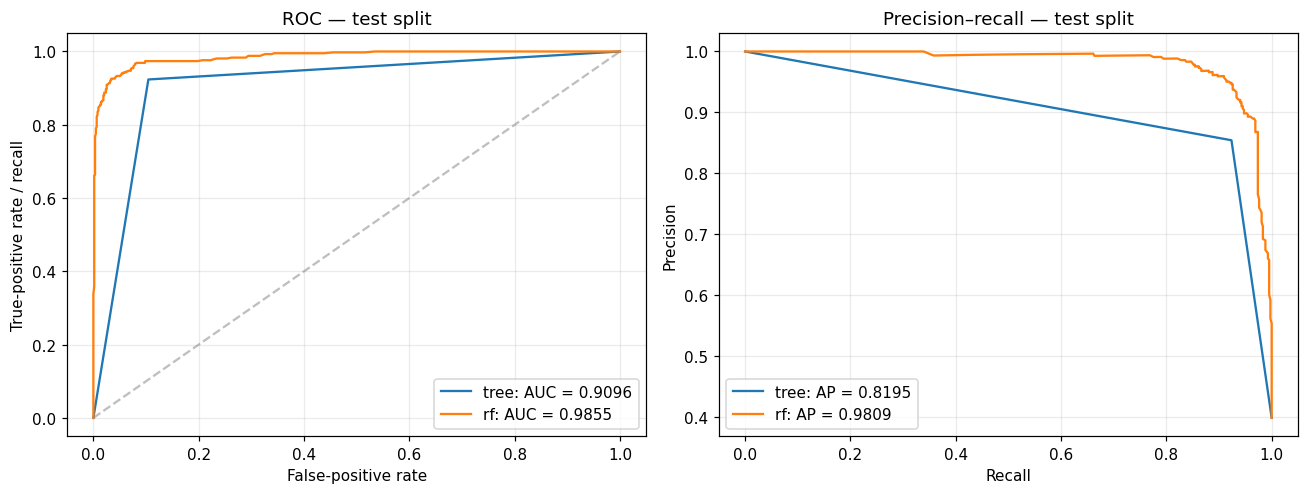

,ROC AUC,average precision
tree,0.909599,0.819507
rf,0.985459,0.980904


In [8]:
tree_evaluation = clone(tree).fit(X_train, y_train)
tree_test_proba = tree_evaluation.predict_proba(X_test)[:, 1]
rf_test_proba = rf.predict_proba(X_test)[:, 1]
curve_metrics = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for name, probabilities in [('tree', tree_test_proba), ('rf', rf_test_proba)]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    curve_metrics[name] = {'ROC AUC': auc, 'average precision': ap}
    axes[0].plot(fpr, tpr, label=f'{name}: AUC = {auc:.4f}')
    axes[1].plot(recall, precision, label=f'{name}: AP = {ap:.4f}')
axes[0].plot([0, 1], [0, 1], '--', color='grey', alpha=0.5)
axes[0].set(xlabel='False-positive rate', ylabel='True-positive rate / recall', title='ROC — test split')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–recall — test split')
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame.from_dict(curve_metrics, orient='index'))

In [9]:
oof = cross_val_predict(rf, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
oof_fprs, oof_recalls, candidate_thresholds = roc_curve(y_train, oof, drop_intermediate=False)
eligible = np.flatnonzero(oof_fprs <= 0.01)
best_recall = oof_recalls[eligible].max()
tied = eligible[oof_recalls[eligible] == best_recall]
threshold_index = tied[np.argmax(candidate_thresholds[tied])]
threshold = float(candidate_thresholds[threshold_index])
oof_fpr_at_t = float(oof_fprs[threshold_index])
oof_recall_at_t = float(oof_recalls[threshold_index])
print(f't = {threshold!r}; OOF FPR = {oof_fpr_at_t:.6f}; OOF recall = {oof_recall_at_t:.6f}')

# Порог зафиксирован по OOF. Ниже он только применяется к test без изменения.
test_flags = (rf_test_proba >= threshold).astype(int)
cm_at_t = confusion_matrix(y_test, test_flags, labels=[0, 1])
tn, fp, fn, tp = cm_at_t.ravel()
test_precision_at_t = precision_score(y_test, test_flags, zero_division=0)
test_recall_at_t = recall_score(y_test, test_flags)
test_fpr_at_t = fp / (tn+fp)
display(pd.DataFrame(cm_at_t, index=['true legitimate (0)', 'true spam (1)'],
                     columns=['predicted legitimate (0)', 'predicted spam (1)']))
display(pd.DataFrame({'precision': [test_precision_at_t], 'recall': [test_recall_at_t],
                      'FPR': [test_fpr_at_t]}))
print(f'Ошибочно отмечены как spam {fp} из {tn+fp} легитимных test-писем.')
display(Markdown(
    f'Цель FPR ≤ 1% на test {"выполнена" if test_fpr_at_t <= .01 else "не выполнена"}: '
    f'FPR = {100*test_fpr_at_t:.3f}%. Порог выбран только на OOF train '
    'с максимальным recall среди допустимых FPR, с выбором самого большого порога при равенстве recall. '
    'Ограничение на OOF не гарантирует такую же долю ошибок на новой конечной выборке; '
    'результат test не использован для изменения порога.'))

t = 0.72; OOF FPR = 0.009494; OOF recall = 0.822593


,predicted legitimate (0),predicted spam (1)
true legitimate (0),624,8
true spam (1),61,358


,precision,recall,FPR
0,0.978142,0.854415,0.012658


Ошибочно отмечены как spam 8 из 632 легитимных test-писем.


Цель FPR ≤ 1% на test не выполнена: FPR = 1.266%. Порог выбран только на OOF train с максимальным recall среди допустимых FPR, с выбором самого большого порога при равенстве recall. Ограничение на OOF не гарантирует такую же долю ошибок на новой конечной выборке; результат test не использован для изменения порога.

In [10]:
perm = permutation_importance(rf, X_test, y_test, n_repeats=10,
                              random_state=SEED, scoring='accuracy')
impurity_importance = pd.Series(rf.feature_importances_, index=feature_names)
permutation_mean = pd.Series(perm.importances_mean, index=feature_names)
display(Markdown('**Top five: mean decrease in impurity (MDI)**'))
display(impurity_importance.sort_values(ascending=False).head(5).rename('MDI importance').to_frame())
display(Markdown('**Top five: permutation importance on the test split**'))
display(permutation_mean.sort_values(ascending=False).head(5).rename('mean accuracy decrease').to_frame())
mdi_ranks = impurity_importance.rank(ascending=False, method='min')
perm_ranks = permutation_mean.rank(ascending=False, method='min')
example_feature = (mdi_ranks-perm_ranks).abs().idxmax()
display(Markdown(
    f'Например, `{example_feature}`: место по MDI = {int(mdi_ranks[example_feature])}, '
    f'по permutation = {int(perm_ranks[example_feature])}; MDI = {impurity_importance[example_feature]:.6f}, '
    f'снижение accuracy после перестановки = {permutation_mean[example_feature]:.6f}. '
    'MDI суммирует взвешенные уменьшения impurity на обучающих разбиениях деревьев и затем '
    'нормируется. Permutation importance измеряет изменение accuracy на test при разрушении '
    'связи одного признака с письмами и усредняет десять перестановок. Эти меры отвечают '
    'на разные вопросы: полезные для разбиений признаки могут частично заменяться другими '
    'при предсказании, а MDI также может предпочитать признаки с большим числом вариантов разбиения. '
    'Поэтому ранги и численные масштабы не обязаны совпадать.'))

**Top five: mean decrease in impurity (MDI)**

,MDI importance
char_freq_exclam,0.118510
char_freq_dollar,0.089275
word_freq_remove,0.076415
capital_run_length_average,0.069419
word_freq_free,0.067365


**Top five: permutation importance on the test split**

,mean accuracy decrease
word_freq_remove,0.023026
word_freq_hp,0.017602
word_freq_free,0.008944
char_freq_exclam,0.008754
char_freq_dollar,0.008754


Например, `word_freq_will`: место по MDI = 20, по permutation = 54; MDI = 0.010982, снижение accuracy после перестановки = -0.000856. MDI суммирует взвешенные уменьшения impurity на обучающих разбиениях деревьев и затем нормируется. Permutation importance измеряет изменение accuracy на test при разрушении связи одного признака с письмами и усредняет десять перестановок. Эти меры отвечают на разные вопросы: полезные для разбиений признаки могут частично заменяться другими при предсказании, а MDI также может предпочитать признаки с большим числом вариантов разбиения. Поэтому ранги и численные масштабы не обязаны совпадать.

## Part 3 — Voting

In [11]:
def hard_vote(predictions, weights=None):
    """Return weighted majority labels, breaking exact ties by the smallest label."""
    predictions = np.asarray(predictions, dtype=int)
    n_models, n_samples = predictions.shape
    model_weights = (np.ones(n_models, dtype=float) if weights is None
                     else np.asarray(weights, dtype=float))
    labels = np.unique(np.concatenate((np.array([0], dtype=int), predictions.ravel())))
    counts = np.zeros((len(labels), n_samples), dtype=float)
    columns = np.arange(n_samples)
    for model in range(n_models):
        rows = np.searchsorted(labels, predictions[model])
        counts[rows, columns] += model_weights[model]
    return labels[np.argmax(counts, axis=0)].astype(int)

In [12]:
assert np.array_equal(hard_vote([[0,1,1],[0,1,0],[1,1,0]]), [0,1,0])
assert np.array_equal(hard_vote([[0,1],[1,0]]), [0,0])
assert np.array_equal(hard_vote([[0,1],[1,0]], weights=[1,2]), [1,0])
assert np.array_equal(hard_vote([[2,0],[2,1],[0,1]]), [2,1])
assert np.array_equal(hard_vote([[2,3],[3,2]], weights=[0,0]), [0,0])
assert np.array_equal(hard_vote([[1000000000],[2]], weights=[1,1]), [2])
assert np.array_equal(hard_vote([[0],[0],[0],[1]], weights=[1e16,1,1,1e16]), [0])
assert np.array_equal(hard_vote([[0],[1]], weights=[.3, .1+.2]), [1])
assert hard_vote(np.empty((2,0), dtype=int)).shape == (0,)
vote_input = np.array([[2,0],[2,1],[0,1]])
vote_weights = np.array([1.,2.,3.])
before_input, before_weights = vote_input.copy(), vote_weights.copy()
hard_vote(vote_input, vote_weights)
assert np.array_equal(vote_input, before_input) and np.array_equal(vote_weights, before_weights)
print('hard_vote: примеры, multiclass, нулевые веса, точные ties, порядок суммирования и неизменность проверены.')

fitted_members = [(name, clone(model).fit(X_train, y_train)) for name, model in members]
member_test_labels = np.vstack([model.predict(X_test) for _, model in fitted_members])
manual_vote = hard_vote(member_test_labels)
hard_voter = VotingClassifier(members, voting='hard').fit(X_train, y_train)
vote_agreement = np.mean(manual_vote == hard_voter.predict(X_test))
print(f'Manual hard vote / VotingClassifier agreement: {vote_agreement:.6f}')
assert vote_agreement == 1
disagreement_rows = []
for i, j in [(0,1), (0,2), (1,2)]:
    disagreement_rows.append({'pair': f'{members[i][0]} / {members[j][0]}',
                              'test disagreement': np.mean(member_test_labels[i] != member_test_labels[j])})
display(pd.DataFrame(disagreement_rows).set_index('pair'))

for name, model in members:
    get_cv_scores(name, model)
get_cv_scores('hard voting', VotingClassifier(members, voting='hard'))
get_cv_scores('soft voting', VotingClassifier(members, voting='soft'))
part3_names = ['lr', 'knn', 'tree', 'hard voting', 'soft voting']
display(fold_table({name: cv_scores[name] for name in part3_names}))
best_member_name = max([name for name, _ in members], key=lambda name: cv_scores[name].mean())
best_member = dict(members)[best_member_name]
print(f'Best member chosen by training CV mean: {best_member_name}')
part3_differences = {f'{name} − {best_member_name}': cv_scores[name]-cv_scores[best_member_name]
                     for name in ['hard voting', 'soft voting']}
display(paired_table(part3_differences))
display(Markdown('\n\n'.join(compare_text(name, diff) for name, diff in part3_differences.items())))
display(Markdown('Hard voting объединяет метки, soft voting — средние вероятности. '
                 'Разногласия показывают разнообразие ошибок, но сами по себе не гарантируют улучшения; '
                 'вывод о результате сделан по парным accuracy на одних и тех же folds.'))

hard_vote: примеры, multiclass, нулевые веса, точные ties, порядок суммирования и неизменность проверены.
Manual hard vote / VotingClassifier agreement: 1.000000


,test disagreement
pair,
lr / knn,0.048525
lr / tree,0.096099
knn / tree,0.110371


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
lr,0.939778,0.936609,0.938193,0.930159,0.939683,0.936884,0.003556
knn,0.919176,0.925515,0.898574,0.911111,0.917460,0.914367,0.009132
tree,0.901743,0.920761,0.904913,0.901587,0.909524,0.907706,0.007135
hard voting,0.939778,0.947702,0.936609,0.936508,0.936508,0.939421,0.004326
soft voting,0.938193,0.944532,0.939778,0.939683,0.938095,0.940056,0.002348


Best member chosen by training CV mean: lr


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
hard voting − lr,0.000000,0.011094,-0.001585,0.006349,-0.003175,0.002537,0.005363
soft voting − lr,-0.001585,0.007924,0.001585,0.009524,-0.001587,0.003172,0.004706


hard voting − lr: mean = 0.002537, std = 0.005363; разность внутри разброса folds; данные не позволяют назвать победителя.

soft voting − lr: mean = 0.003172, std = 0.004706; разность внутри разброса folds; данные не позволяют назвать победителя.

Hard voting объединяет метки, soft voting — средние вероятности. Разногласия показывают разнообразие ошибок, но сами по себе не гарантируют улучшения; вывод о результате сделан по парным accuracy на одних и тех же folds.

## Part 4 — Stacking

In [13]:
oof_meta = np.column_stack([
    cross_val_predict(model, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
    for _, model in members])
assert oof_meta.shape == (len(y_train), 3)
manual_meta = LogisticRegression().fit(oof_meta, y_train)
# Эти члены уже независимо обучены на полном train в Part 3.
test_meta = np.column_stack([model.predict_proba(X_test)[:, 1] for _, model in fitted_members])
manual_stack_predictions = manual_meta.predict(test_meta)
stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
stack_predictions = stack.predict(X_test)
coefficient_difference = np.max(np.abs(manual_meta.coef_ - stack.final_estimator_.coef_))
manual_stack_accuracy = accuracy_score(y_test, manual_stack_predictions)
sklearn_stack_accuracy = stack.score(X_test, y_test)
print(f'Maximum absolute coefficient difference: {coefficient_difference:.12g}')
print(f'Identical test predictions: {np.array_equal(manual_stack_predictions, stack_predictions)}')
display(pd.DataFrame({'test accuracy': [manual_stack_accuracy, sklearn_stack_accuracy]},
                     index=['manual OOF stacking', 'StackingClassifier']))
assert np.allclose(manual_meta.coef_, stack.final_estimator_.coef_, atol=1e-10, rtol=1e-10)
assert np.array_equal(manual_stack_predictions, stack_predictions)

naive_meta_features = np.column_stack([
    clone(model).fit(X_train, y_train).predict_proba(X_train)[:, 1] for _, model in members])
naive_meta = LogisticRegression().fit(naive_meta_features, y_train)
meta_coefficients = pd.DataFrame({'naive coefficient': naive_meta.coef_[0],
                                 'OOF coefficient': manual_meta.coef_[0]},
                                index=[name for name, _ in members])
display(meta_coefficients)
get_cv_scores('stacking', StackingClassifier(members, LogisticRegression(), cv=cv))
display(fold_table({name: cv_scores[name] for name in ['stacking', 'soft voting', best_member_name]}))
part4_differences = {
    f'stacking − {best_member_name}': cv_scores['stacking']-cv_scores[best_member_name],
    'stacking − soft voting': cv_scores['stacking']-cv_scores['soft voting']}
display(paired_table(part4_differences))
tree_naive_weight = meta_coefficients.loc['tree', 'naive coefficient']
tree_oof_weight = meta_coefficients.loc['tree', 'OOF coefficient']
display(Markdown(
    f'Коэффициент дерева: naive = {tree_naive_weight:.6f}, OOF = {tree_oof_weight:.6f}; '
    f'изменение OOF − naive = {tree_oof_weight-tree_naive_weight:.6f}. '
    'Полное нерегуляризованное дерево запоминает обучающие строки, поэтому in-sample вероятности '
    'создают для naive meta-learner слишком благоприятное представление о его качестве. '
    'OOF-предсказания получены для строк, которых соответствующий член не видел при обучении, '
    'и показывают его ошибки обобщения; мета-модель перераспределяет коэффициенты на этой основе. '
    'Коэффициенты не являются нормированными долями доверия, поскольку это коэффициенты логистической регрессии.'))
display(Markdown('\n\n'.join(compare_text(name, diff) for name, diff in part4_differences.items())))

Maximum absolute coefficient difference: 0
Identical test predictions: True


,test accuracy
manual OOF stacking,0.944814
StackingClassifier,0.944814


,naive coefficient,OOF coefficient
lr,1.977933,4.250263
knn,1.726984,2.144360
tree,8.327275,1.716197


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
stacking,0.941363,0.949287,0.928685,0.926984,0.946032,0.938470,0.009058
soft voting,0.938193,0.944532,0.939778,0.939683,0.938095,0.940056,0.002348
lr,0.939778,0.936609,0.938193,0.930159,0.939683,0.936884,0.003556


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
stacking − lr,0.001585,0.012678,-0.009509,-0.003175,0.006349,0.001586,0.007635
stacking − soft voting,0.003170,0.004754,-0.011094,-0.012698,0.007937,-0.001586,0.008572


Коэффициент дерева: naive = 8.327275, OOF = 1.716197; изменение OOF − naive = -6.611078. Полное нерегуляризованное дерево запоминает обучающие строки, поэтому in-sample вероятности создают для naive meta-learner слишком благоприятное представление о его качестве. OOF-предсказания получены для строк, которых соответствующий член не видел при обучении, и показывают его ошибки обобщения; мета-модель перераспределяет коэффициенты на этой основе. Коэффициенты не являются нормированными долями доверия, поскольку это коэффициенты логистической регрессии.

stacking − lr: mean = 0.001586, std = 0.007635; разность внутри разброса folds; данные не позволяют назвать победителя.

stacking − soft voting: mean = -0.001586, std = 0.008572; разность внутри разброса folds; данные не позволяют назвать победителя.

## Part 5 — AdaBoost and label noise

In [14]:
def adaboost_step(y_true, y_pred, weights):
    """Return alpha and a fresh normalized weight array for one AdaBoost round."""
    w = np.array(weights, dtype=float, copy=True)
    wrong = np.asarray(y_pred) != np.asarray(y_true)
    epsilon = float(w[wrong].sum() / w.sum())
    if epsilon == 0:
        return math.inf, w / w.sum()
    alpha = float(math.log((1 - epsilon) / epsilon))
    w[wrong] *= math.exp(alpha)
    return alpha, w / w.sum()

In [15]:
# Check the specified examples, negative labels, non-unit sums and immutability.
ada_examples = [
    ([1, 1, 0, 0], [1, 0, 0, 0], [1, 1, 1, 1],
     math.log(3), [1/6, 1/2, 1/6, 1/6]),
    ([1, 1, 1, 0], [0, 0, 0, 0], [1, 1, 1, 1],
     -math.log(3), [1/6, 1/6, 1/6, 1/2]),
    ([1, 0], [0, 0], [1, 1], 0.0, [0.5, 0.5]),
    ([1, 0, 1], [1, 0, 1], [2, 2, 4], math.inf, [0.25, 0.25, 0.5]),
    ([-1, 1, 1, -1], [-1, 1, -1, -1], [0.1, 0.2, 0.1, 0.1],
     math.log(4), [0.125, 0.25, 0.5, 0.125]),
    ([1, 0], [0, 0], [0, 2], math.inf, [0.0, 1.0]),
]
for true_labels, predictions, initial_weights, expected_alpha, expected_w in ada_examples:
    originals = [np.asarray(a).copy() for a in (true_labels, predictions, initial_weights)]
    result_alpha, result_w = adaboost_step(
        y_true=true_labels, y_pred=predictions, weights=initial_weights)
    assert isinstance(result_alpha, float)
    assert result_w.shape == (len(true_labels),) and result_w.dtype.kind == "f"
    assert np.isclose(result_alpha, expected_alpha) if np.isfinite(expected_alpha) else math.isinf(result_alpha)
    np.testing.assert_allclose(result_w, expected_w)
    for arg, original in zip((true_labels, predictions, initial_weights), originals):
        np.testing.assert_array_equal(arg, original)
print("adaboost_step: all specified examples and edge checks passed.")

adaboost_step: all specified examples and edge checks passed.


### Три пня из лекционного примера

In [16]:
x = np.arange(1, 11)
y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
stump_1 = np.where(x <= 3.5, 1, 0)
stump_2 = np.where(x <= 9.5, 1, 0)
stump_3 = np.where(x <= 6.5, 0, 1)
w_toy = np.full(10, 0.1)
toy_rows = []
for round_number, predictions in enumerate([stump_1, stump_2, stump_3], start=1):
    epsilon = float(w_toy[predictions != y_toy].sum() / w_toy.sum())
    alpha, w_toy = adaboost_step(y_toy, predictions, w_toy)
    toy_rows.append({"round": round_number, "epsilon": epsilon, "alpha": alpha,
                     **{f"w{x_i}": w_toy[x_i - 1] for x_i in x}})
toy_table = pd.DataFrame(toy_rows).set_index("round")
display(toy_table)
np.testing.assert_allclose(toy_table["epsilon"], [3/10, 3/14, 2/11])
np.testing.assert_allclose(toy_table["alpha"], np.log([7/3, 11/3, 9/2]))
display(Markdown(
    "Для трёх заданных пней получены ε = 0.300000, 0.214286 и 0.181818, "
    "α = 0.847298, 1.299283 и 1.504077. В первом раунде вес верной строки "
    "равен 0.071429, ошибочной — 0.166667: после округления это 0.071 и 0.167 "
    "из приведённого в условии слайда; далее используются именно обновлённые веса."))

,epsilon,alpha,w1,w2,w3,w4,w5,w6,w7,w8,w9,w10
round,,,,,,,,,,,,
1,0.300000,0.847298,0.071429,0.071429,0.071429,0.071429,0.071429,0.071429,0.166667,0.166667,0.166667,0.071429
2,0.214286,1.299283,0.045455,0.045455,0.045455,0.166667,0.166667,0.166667,0.106061,0.106061,0.106061,0.045455
3,0.181818,1.504077,0.125000,0.125000,0.125000,0.101852,0.101852,0.101852,0.064815,0.064815,0.064815,0.125000


Для трёх заданных пней получены ε = 0.300000, 0.214286 и 0.181818, α = 0.847298, 1.299283 и 1.504077. В первом раунде вес верной строки равен 0.071429, ошибочной — 0.166667: после округления это 0.071 и 0.167 из приведённого в условии слайда; далее используются именно обновлённые веса.

### Проверка scikit-learn и выбор числа раундов по обучающим фолдам

,epsilon_manual,epsilon_sklearn,alpha_manual,alpha_sklearn
round,,,,
1,0.215033,0.215033,1.294848,1.294848
2,0.238168,0.238168,1.162747,1.162747
3,0.290638,0.290638,0.892287,0.892287
4,0.275102,0.275102,0.968890,0.968890
5,0.302270,0.302270,0.836510,0.836510


Largest absolute epsilon difference, first 5 rounds: 5.551e-17
Largest absolute alpha difference, first 5 rounds:   2.220e-16


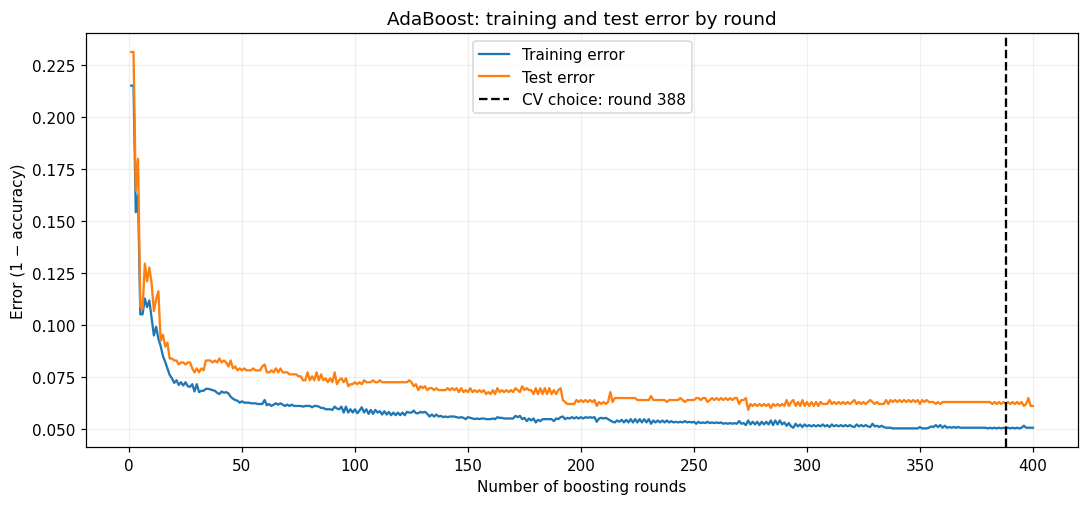

Chosen round (training CV only): 388
Mean CV accuracy at chosen round: 0.942597
Test error at chosen round: 0.061846
Lowest test error: 0.058991, first reached at round 274
SE of test accuracy at chosen round: 0.007430
Absolute test-error difference: 0.002854
Difference exceeds one SE: False


По обучающим фолдам выбран раунд **388**, а минимум уже построенной тестовой кривой впервые достигается на раунде **274**. Ошибка выбранного раунда 0.0618, минимум тестовой ошибки 0.0590; разность 0.0029 не превышает одну стандартную ошибку 0.0074. Тестовый минимум приведён для сравнения после выбора и не меняет выбранное число раундов; расхождение оптимумов возможно из-за вариации конечных выборок.

In [17]:
ada.fit(X_train, y_train)
w_check = np.full(len(y_train), 1 / len(y_train))
check_rows = []
for t, stump in enumerate(ada.estimators_[:5]):
    stump_prediction = stump.predict(X_train)
    epsilon = float(w_check[stump_prediction != y_train].sum() / w_check.sum())
    alpha, w_check = adaboost_step(y_train, stump_prediction, w_check)
    check_rows.append({
        "round": t + 1, "epsilon_manual": epsilon,
        "epsilon_sklearn": ada.estimator_errors_[t],
        "alpha_manual": alpha, "alpha_sklearn": ada.estimator_weights_[t],
    })
ada_check = pd.DataFrame(check_rows).set_index("round")
display(ada_check)
max_epsilon_diff = float(np.abs(ada_check.epsilon_manual - ada_check.epsilon_sklearn).max())
max_alpha_diff = float(np.abs(ada_check.alpha_manual - ada_check.alpha_sklearn).max())
print(f"Largest absolute epsilon difference, first 5 rounds: {max_epsilon_diff:.3e}")
print(f"Largest absolute alpha difference, first 5 rounds:   {max_alpha_diff:.3e}")
np.testing.assert_allclose(ada_check.epsilon_manual, ada_check.epsilon_sklearn, atol=1e-12)
np.testing.assert_allclose(ada_check.alpha_manual, ada_check.alpha_sklearn, atol=1e-12)

# Round selection uses only the five validation folds of the training split.
ada_fold_curves = []
for train_idx, valid_idx in cv.split(X_train, y_train):
    fold_ada = clone(ada).fit(X_train[train_idx], y_train[train_idx])
    fold_curve = np.array(list(fold_ada.staged_score(X_train[valid_idx], y_train[valid_idx])))
    assert len(fold_curve) == 400
    ada_fold_curves.append(fold_curve)
ada_mean_cv_curve = np.mean(ada_fold_curves, axis=0)
chosen_round = int(np.argmax(ada_mean_cv_curve) + 1)

ada_train_error = 1 - np.array(list(ada.staged_score(X_train, y_train)))
ada_test_accuracy = np.array(list(ada.staged_score(X_test, y_test)))
ada_test_error = 1 - ada_test_accuracy
assert len(ada_train_error) == len(ada_test_error) == 400
best_test_round = int(np.argmin(ada_test_error) + 1)
chosen_test_error = float(ada_test_error[chosen_round - 1])
best_test_error = float(ada_test_error[best_test_round - 1])
chosen_test_accuracy = float(ada_test_accuracy[chosen_round - 1])
chosen_test_se = float(np.sqrt(chosen_test_accuracy * (1 - chosen_test_accuracy) / len(y_test)))
errors_differ_more_than_se = abs(chosen_test_error - best_test_error) > chosen_test_se

fig, ax = plt.subplots(figsize=(10, 4.7))
rounds = np.arange(1, 401)
ax.plot(rounds, ada_train_error, label="Training error")
ax.plot(rounds, ada_test_error, label="Test error")
ax.axvline(chosen_round, color="black", linestyle="--", label=f"CV choice: round {chosen_round}")
ax.set(xlabel="Number of boosting rounds", ylabel="Error (1 − accuracy)",
       title="AdaBoost: training and test error by round")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print(f"Chosen round (training CV only): {chosen_round}")
print(f"Mean CV accuracy at chosen round: {ada_mean_cv_curve[chosen_round - 1]:.6f}")
print(f"Test error at chosen round: {chosen_test_error:.6f}")
print(f"Lowest test error: {best_test_error:.6f}, first reached at round {best_test_round}")
print(f"SE of test accuracy at chosen round: {chosen_test_se:.6f}")
print(f"Absolute test-error difference: {abs(chosen_test_error - best_test_error):.6f}")
print(f"Difference exceeds one SE: {errors_differ_more_than_se}")
display(Markdown(
    f"По обучающим фолдам выбран раунд **{chosen_round}**, а минимум уже построенной "
    f"тестовой кривой впервые достигается на раунде **{best_test_round}**. "
    f"Ошибка выбранного раунда {chosen_test_error:.4f}, минимум тестовой ошибки "
    f"{best_test_error:.4f}; разность {abs(chosen_test_error - best_test_error):.4f} "
    f"{'превышает' if errors_differ_more_than_se else 'не превышает'} "
    f"одну стандартную ошибку {chosen_test_se:.4f}. "
    "Тестовый минимум приведён для сравнения после выбора и не меняет выбранное число раундов; "
    "расхождение оптимумов возможно из-за вариации конечных выборок."))

### Шум в обучающих метках и конечные веса AdaBoost

In [18]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx

ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "rf": rf, "ada200": ada200}
clean_noise_accuracy = {}
for name, model in noise_models.items():
    clean_model = clone(model).fit(X_train, y_train)
    clean_noise_accuracy[name] = float(clean_model.score(X_test, y_test))
noisy_accuracy = {name: [] for name in noise_models}
final_weight_shares = []
initial_weight_shares = []
weight_rows = []
for r in range(5):
    y_noisy, idx = flip_labels(y_train, 0.20, SEED + r)
    initial_share = len(idx) / len(y_train)
    initial_weight_shares.append(initial_share)
    for name, model in noise_models.items():
        noisy_model = clone(model).fit(X_train, y_noisy)
        noisy_accuracy[name].append(float(noisy_model.score(X_test, y_test)))
        if name == "ada200":
            w_final = np.full(len(y_train), 1 / len(y_train))
            for stump in noisy_model.estimators_:
                _, w_final = adaboost_step(y_noisy, stump.predict(X_train), w_final)
            final_share = float(w_final[idx].sum())
            final_weight_shares.append(final_share)
            weight_rows.append({"draw": r, "noise_seed": SEED + r,
                                "flipped_rows": len(idx), "initial_weight_share": initial_share,
                                "final_weight_share": final_share,
                                "fitted_rounds": len(noisy_model.estimators_)})
noisy_accuracy = {name: np.array(values) for name, values in noisy_accuracy.items()}
part5_noise_losses = {
    name: clean_noise_accuracy[name] - noisy_accuracy[name] for name in noise_models}
part5_noise_summary = pd.DataFrame({
    name: {
        "clean_accuracy": clean_noise_accuracy[name],
        "noisy_accuracy_mean": noisy_accuracy[name].mean(),
        "noisy_accuracy_std": noisy_accuracy[name].std(ddof=0),
        "loss_mean": part5_noise_losses[name].mean(),
        "loss_std": part5_noise_losses[name].std(ddof=0),
    } for name in noise_models
}).T
part5_weight_shares = np.array(final_weight_shares)
display(part5_noise_summary)
display(pd.DataFrame({
    "clean_accuracy": part5_noise_summary["clean_accuracy"].map(lambda v: f"{v:.6f}"),
    "20% noisy accuracy (mean ± std)": [
        f"{noisy_accuracy[name].mean():.6f} ± {noisy_accuracy[name].std(ddof=0):.6f}"
        for name in part5_noise_summary.index],
    "loss (mean ± std)": [
        f"{part5_noise_losses[name].mean():.6f} ± {part5_noise_losses[name].std(ddof=0):.6f}"
        for name in part5_noise_summary.index],
}))
print("The five noisy test accuracies (clean test labels in every draw):")
display(pd.DataFrame(noisy_accuracy, index=pd.Index(range(5), name="draw")))
print("Five losses per model, paired by the same noise draw:")
display(pd.DataFrame(part5_noise_losses, index=pd.Index(range(5), name="draw")))
loss_pairs = {
    "tree loss − rf loss": part5_noise_losses["tree"] - part5_noise_losses["rf"],
    "tree loss − ada200 loss": part5_noise_losses["tree"] - part5_noise_losses["ada200"],
    "rf loss − ada200 loss": part5_noise_losses["rf"] - part5_noise_losses["ada200"],
}
print("Paired differences of losses; positive means greater degradation for the first model:")
display(paired_table(loss_pairs))
print("AdaBoost weight share assigned to the flipped rows:")
display(pd.DataFrame(weight_rows).set_index("draw"))
print(f"Initial flipped-row weight share: {np.mean(initial_weight_shares):.6f}")
print(f"Final flipped-row weight share: {part5_weight_shares.mean():.6f} ± "
      f"{part5_weight_shares.std(ddof=0):.6f}")

# Compare paired losses using exactly the assignment's spread rule.
loss_order = sorted(noise_models, key=lambda name: part5_noise_losses[name].mean(), reverse=True)
loss_conclusions = []
for left, right in [("tree", "rf"), ("tree", "ada200"), ("rf", "ada200")]:
    diff = part5_noise_losses[left] - part5_noise_losses[right]
    mean_diff, std_diff = float(diff.mean()), float(diff.std(ddof=0))
    if abs(mean_diff) <= std_diff:
        finding = "разность внутри разброса; эти данные не разделяют модели по потере accuracy"
    elif mean_diff > 0:
        finding = f"потеря {left} больше потери {right} за пределами разброса"
    else:
        finding = f"потеря {right} больше потери {left} за пределами разброса"
    loss_conclusions.append(
        f"{left} − {right}: {mean_diff:.4f} ± {std_diff:.4f}; {finding}.")
largest_loss_model = loss_order[0]
largest_separated = all(
    (part5_noise_losses[largest_loss_model] - part5_noise_losses[other]).mean()
    > (part5_noise_losses[largest_loss_model] - part5_noise_losses[other]).std(ddof=0)
    for other in loss_order[1:])
comparison_text = " ".join(loss_conclusions)
concentration_change = part5_weight_shares.mean() - np.mean(initial_weight_shares)
display(Markdown(
    f"По средним наблюдаемым потерям порядок от большей к меньшей: "
    f"**{' > '.join(loss_order)}**; наибольшая средняя потеря у {largest_loss_model} "
    f"({part5_noise_losses[largest_loss_model].mean():.4f} ± "
    f"{part5_noise_losses[largest_loss_model].std(ddof=0):.4f}). "
    + (f"Её превышение над обеими другими потерями выходит за пределы парного разброса. "
       if largest_separated else
       "Её нельзя объявлять однозначно наибольшей относительно всех моделей: хотя бы одно сравнение внутри разброса. ")
    + comparison_text + "\n\n"
    + f"Одиночное неограниченное дерево может подгонять неверные обучающие метки; "
    f"его потеря {part5_noise_losses['tree'].mean():.4f}. "
    f"В лесу усреднение деревьев снижает вариацию "
    f"(потеря {part5_noise_losses['rf'].mean():.4f}). "
    f"AdaBoost повышает вес трудно объясняемых строк, включая строки с перевёрнутой меткой: "
    f"их средняя доля конечного веса {part5_weight_shares.mean():.4f} "
    f"против исходных {np.mean(initial_weight_shares):.4f}, изменение {concentration_change:+.4f}; "
    f"его потеря {part5_noise_losses['ada200'].mean():.4f}. "
    "При этом слабые пни ограничивают сложность отдельных правил, поэтому концентрация веса "
    "сама по себе не определяет порядок тестовых потерь; вывод о порядке сделан по измеренным парным разностям."))

,clean_accuracy,noisy_accuracy_mean,noisy_accuracy_std,loss_mean,loss_std
tree,0.906755,0.733968,0.014991,0.172788,0.014991
rf,0.946717,0.901047,0.006619,0.045671,0.006619
ada200,0.936251,0.910752,0.010738,0.025500,0.010738


,clean_accuracy,20% noisy accuracy (mean ± std),loss (mean ± std)
tree,0.906755,0.733968 ± 0.014991,0.172788 ± 0.014991
rf,0.946717,0.901047 ± 0.006619,0.045671 ± 0.006619
ada200,0.936251,0.910752 ± 0.010738,0.025500 ± 0.010738


The five noisy test accuracies (clean test labels in every draw):


,tree,rf,ada200
draw,,,
0,0.714558,0.891532,0.905804
1,0.732636,0.904853,0.930542
2,0.756422,0.910561,0.901998
3,0.744053,0.901998,0.901998
4,0.722169,0.896289,0.913416


Five losses per model, paired by the same noise draw:


,tree,rf,ada200
draw,,,
0,0.192198,0.055186,0.030447
1,0.174120,0.041865,0.005709
2,0.150333,0.036156,0.034253
3,0.162702,0.044719,0.034253
4,0.184586,0.050428,0.022835


... (2 outputs left out)

AdaBoost weight share assigned to the flipped rows:


,noise_seed,flipped_rows,initial_weight_share,final_weight_share,fitted_rounds
draw,,,,,
0,2962,631,0.200127,0.398271,200
1,2963,631,0.200127,0.391828,200
2,2964,631,0.200127,0.400506,200
3,2965,631,0.200127,0.393479,200
4,2966,631,0.200127,0.390288,200


Initial flipped-row weight share: 0.200127
Final flipped-row weight share: 0.394875 ± 0.003886


По средним наблюдаемым потерям порядок от большей к меньшей: **tree > rf > ada200**; наибольшая средняя потеря у tree (0.1728 ± 0.0150). Её превышение над обеими другими потерями выходит за пределы парного разброса. tree − rf: 0.1271 ± 0.0092; потеря tree больше потери rf за пределами разброса. tree − ada200: 0.1473 ± 0.0209; потеря tree больше потери ada200 за пределами разброса. rf − ada200: 0.0202 ± 0.0123; потеря rf больше потери ada200 за пределами разброса.

Одиночное неограниченное дерево может подгонять неверные обучающие метки; его потеря 0.1728. В лесу усреднение деревьев снижает вариацию (потеря 0.0457). AdaBoost повышает вес трудно объясняемых строк, включая строки с перевёрнутой меткой: их средняя доля конечного веса 0.3949 против исходных 0.2001, изменение +0.1947; его потеря 0.0255. При этом слабые пни ограничивают сложность отдельных правил, поэтому концентрация веса сама по себе не определяет порядок тестовых потерь; вывод о порядке сделан по измеренным парным разностям.

## Part 6 — Recommendation and reproducibility

In [19]:
rf_comparisons = {f'rf − {name}': cv_scores['rf']-values
                  for name, values in cv_scores.items() if name != 'rf'}
display(Markdown('**Дополнительные парные сравнения для рекомендации**'))
display(paired_table(rf_comparisons))
inside_comparisons = [name for name, diff in {**part1_differences, **part3_differences,
                                             **part4_differences, **rf_comparisons}.items()
                      if abs(diff.mean()) <= diff.std(ddof=0)]
inside_text = '; '.join(inside_comparisons) if inside_comparisons else 'среди показанных сравнений таких нет'
recommendation = (
    f'Рекомендую фиксированный Random Forest (300 деревьев) с порогом t = {threshold!r}: '
    f'OOF FPR = {oof_fpr_at_t:.4f}, recall = {oof_recall_at_t:.4f}. '
    f'При единственном применении к test получены precision = {test_precision_at_t:.4f}, '
    f'recall = {test_recall_at_t:.4f}, FPR = {test_fpr_at_t:.4f} ({fp} из {tn+fp} легитимных писем), '
    f'поэтому ограничение 1% {"выполнено" if test_fpr_at_t <= .01 else "не выполнено"}. '
    f'Его accuracy при стандартном решении модели составляет CV {cv_scores["rf"].mean():.4f} '
    f'± {cv_scores["rf"].std(ddof=0):.4f} и test {rf_test_accuracy:.4f} '
    f'с SE {rf_test_se:.4f}, но для фильтра существенно именно качество при выбранном пороге. '
    f'Внутри разброса folds лежат сравнения: {inside_text}, поэтому они не обосновывают выбор победителя. '
    f'При 20% ошибочных train-меток средняя потеря test accuracy леса равна '
    f'{np.asarray(part5_noise_losses["rf"]).mean():.4f}; шумовые различия интерпретированы '
    'по парным потерям пяти одинаковых draws в Part 5. '
    'Это рекомендация для данного учебного корпуса; порог после просмотра test не перенастраивается.'
)
display(Markdown(recommendation))

**Дополнительные парные сравнения для рекомендации**

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
rf − tree,0.031696,0.030111,0.036450,0.047619,0.049206,0.039016,0.007967
rf − bag,0.001585,0.011094,0.001585,0.006349,0.009524,0.006027,0.003936
rf − lr,-0.006339,0.014263,0.003170,0.019048,0.019048,0.009838,0.009954
rf − bag_lr,-0.006339,0.012678,0.004754,0.017460,0.019048,0.009520,0.009360
rf − knn,0.014263,0.025357,0.042789,0.038095,0.041270,0.032355,0.010932
rf − hard voting,-0.006339,0.003170,0.004754,0.012698,0.022222,0.007301,0.009606
rf − soft voting,-0.004754,0.006339,0.001585,0.009524,0.020635,0.006666,0.008481
rf − stacking,-0.007924,0.001585,0.012678,0.022222,0.012698,0.008252,0.010398


Рекомендую фиксированный Random Forest (300 деревьев) с порогом t = 0.72: OOF FPR = 0.0095, recall = 0.8226. При единственном применении к test получены precision = 0.9781, recall = 0.8544, FPR = 0.0127 (8 из 632 легитимных писем), поэтому ограничение 1% не выполнено. Его accuracy при стандартном решении модели составляет CV 0.9467 ± 0.0086 и test 0.9467 с SE 0.0069, но для фильтра существенно именно качество при выбранном пороге. Внутри разброса folds лежат сравнения: bag_lr − lr; hard voting − lr; soft voting − lr; stacking − lr; stacking − soft voting; rf − lr; rf − hard voting; rf − soft voting; rf − stacking, поэтому они не обосновывают выбор победителя. При 20% ошибочных train-меток средняя потеря test accuracy леса равна 0.0457; шумовые различия интерпретированы по парным потерям пяти одинаковых draws в Part 5. Это рекомендация для данного учебного корпуса; порог после просмотра test не перенастраивается.

### Reproducibility

- В начале показаны версии библиотек и **SEED = 2962**.
- Данные и `requirements.txt` взяты из starter без изменений; scaler находится внутри pipelines.
- Во всех частях одинаковые train/test split и пять folds; ручные повторные fit используют `clone`.
- Все выводы и графики сохранены после выполнения notebook сверху вниз в чистом kernel.
- История локального Git содержит последовательные коммиты: starter, Parts 1–2, Parts 3–4,
  Parts 5–6 и выполненный notebook. После push сдаётся ссылка на финальный коммит.